<div dir="rtl" lang="he" style="text-align:right;line-height:1.65">
<h2>Apache Kafka עם Python — מחברת למידה הדרגתית</h2>
<p><b>ד״ר פאול אברהמי | נובמבר 2026</b></p>
<p>המחברת מלווה את מצגת הסטודנטים. היא מבוססת רעיונית על ארבעת המודולים של
<a href="https://github.com/conduktor/kafka-beginners-course">Kafka for Beginners מאת Conduktor</a>.
המאגר המקורי כתוב ב־Java. המחברת היא <b>עיבוד לימודי מקורי ל־Python</b>, ולא תרגום שורה־מול־שורה או הפעלה של Kafka Streams.</p>
<p>גרסת המאגר שנבדקה: <code dir="ltr" style="direction:ltr;unicode-bidi:isolate">bce0dfe60b076b9affc2148a8783faed8dc9559d</code> מ־19.11.2026.</p>
<p><b>התחלה:</b> הכינו את סביבת הפרויקט עם <code dir="ltr" style="direction:ltr;unicode-bidi:isolate">uv</code>, פתחו את המחברת ב־Cursor
ובחרו את ה־Kernel של <code dir="ltr" style="direction:ltr;unicode-bidi:isolate">.venv</code> לפי ההנחיות להלן. לאחר מכן בחרו <code dir="ltr" style="direction:ltr;unicode-bidi:isolate">Restart Kernel and Run All</code>.</p>
<p>ברירת המחדל משתמשת רק בספרייה התקנית ובנתונים סינתטיים שנמצאים במחברת.
לאחר הכנת הסביבה, מסלול הלמידה הלא מקוון אינו דורש אינטרנט או חיבור ל־Kafka.
הורדת התלויות בהקמה הראשונית עשויה לדרוש חיבור לאינטרנט.</p>
<p><b>גרסת היעד: Python 3.13.12.</b> הקובץ <code dir="ltr" style="direction:ltr;unicode-bidi:isolate">.python-version</code> בחבילת הפרויקט מצמיד את הסביבה לגרסה זו. כל חיבור חי דורש הפעלה מפורשת של הדגל המתאים.
אין צורך לשכפל את מאגר GitHub כדי להריץ את המחברת; עובדים מתוך חבילת הפרויקט המצורפת.</p>
<p>בכל שלב מופיעים הסבר, קוד קצר ותצפית או שאלה. ארבעה תרגילים כוללים פתרון נפתח.</p>
</div>

<div dir="rtl" lang="he" style="text-align:right;line-height:1.65">
<h2>מה עושים במחברת?</h2>
<p><b>המטרה:</b> להבין מה קורה לאירוע מהרגע שנוצר ועד שמפיקים ממנו תשובה.
נעקוב אחרי אירוע אחד מתוך <code dir="ltr" style="direction:ltr;unicode-bidi:isolate">FIXTURE</code>: מזהה <code dir="ltr" style="direction:ltr;unicode-bidi:isolate">synthetic-001</code>,
אתר <code dir="ltr" style="direction:ltr;unicode-bidi:isolate">en.wikipedia.org</code>, זמן <code dir="ltr" style="direction:ltr;unicode-bidi:isolate">12:00:02 UTC</code> ו־<code dir="ltr" style="direction:ltr;unicode-bidi:isolate">bot=True</code>.
זהו נתון מומצא לתרגול. הוא יוסיף 1 לספירת Bots ולחלון עשר השניות שמתחיל ב־12:00:00.</p>
<p><b>ברירת המחדל מקומית:</b> שלושת דגלי <code dir="ltr" style="direction:ltr;unicode-bidi:isolate">RUN_LIVE_...</code> הם <code dir="ltr" style="direction:ltr;unicode-bidi:isolate">False</code>.
מעבדים עשרה אירועים ברשימות ובמילונים של Python; לא מתחברים לשרת Kafka.
הגדרת פונקציה באמצעות <code dir="ltr" style="direction:ltr;unicode-bidi:isolate">def</code> מכינה אותה לשימוש — היא אינה מפעילה את תוכנה.</p>
<p><b>במסלול האמיתי:</b> מפעילים שרת Kafka, מאפשרים את הדגל המתאים, ושולחים וקוראים רשומות דרך הרשת.
הספרייה <code dir="ltr" style="direction:ltr;unicode-bidi:isolate">confluent-kafka</code> היא <b>לקוח Python, לא שרת Kafka</b>.
התקנתה אינה מפעילה שרת ואינה דורשת חשבון Confluent כדי להתחבר לשרת המקומי.</p>
<p>זו התאמה לימודית מקורית ל־Python של ארבעת מודולי Java במאגר Conduktor.
הספירות במחברת הן חישובי Python על דגימה; הן אינן הפעלה של Kafka Streams.</p>
</div>

<div dir="rtl" lang="he" style="text-align:right"><h2>ציור 1 — התרגול המקומי</h2></div>

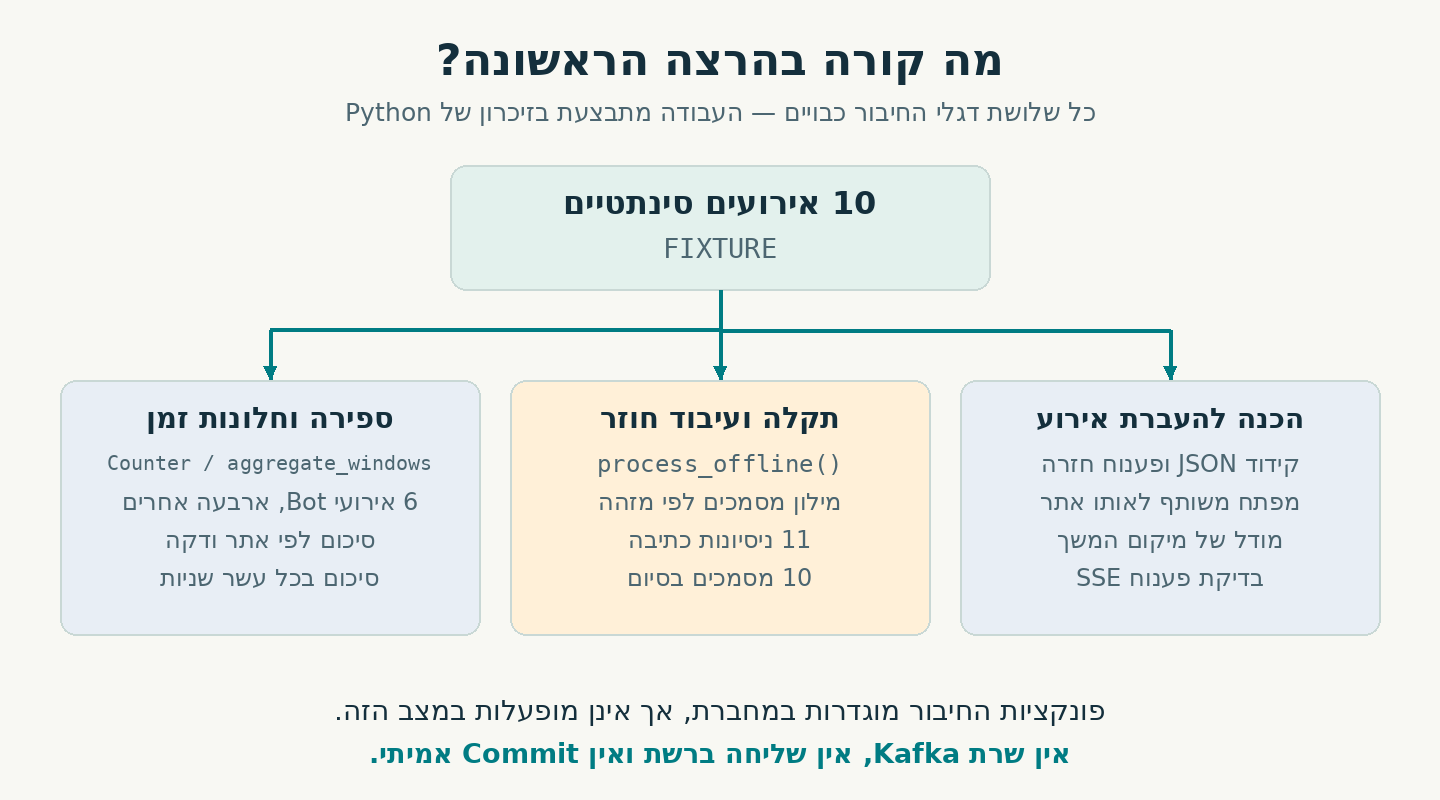

<div dir="rtl" lang="he" style="text-align:right;line-height:1.65"><p>אותם נתוני דוגמה משמשים כמה תרגילים. החצים מציינים שימוש בנתונים; אין כאן שרת Kafka סמוי.</p></div>

<div dir="rtl" lang="he" style="text-align:right"><h2>ציור 2 — החיבור הראשון לשרת</h2></div>

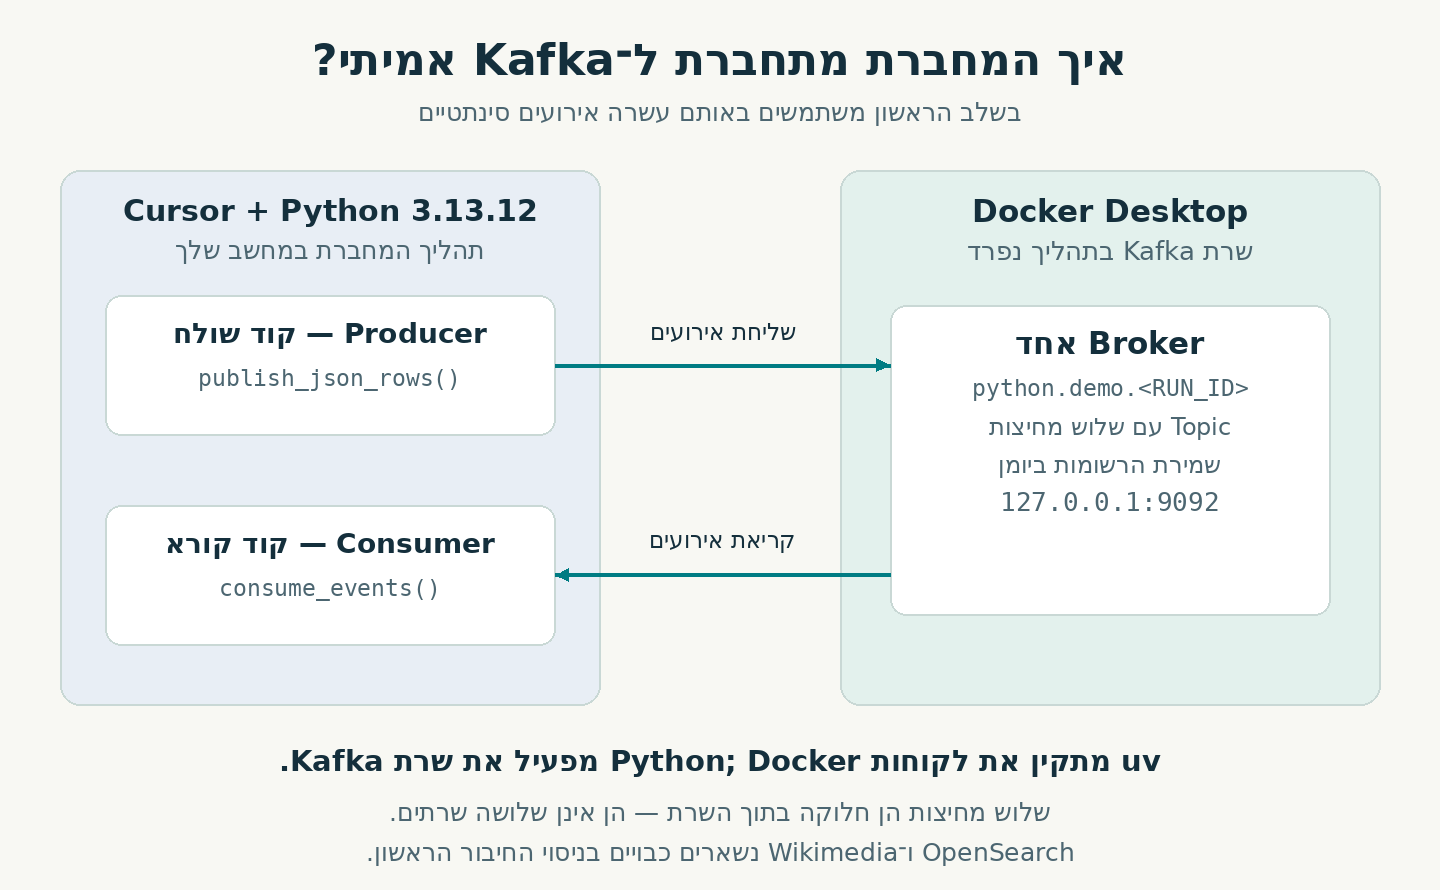

<div dir="rtl" lang="he" style="text-align:right;line-height:1.65"><p>במסלול המקומי האמיתי, המחברת וה־Broker רצים באותו מחשב בתהליכים נפרדים. uv מנהל את סביבת Python, ו־Docker מפעיל את השרת.</p></div>

<div dir="rtl" lang="he" style="text-align:right;line-height:1.65">
<h2>מפת השיעור — חמישה חלקים</h2>
<table>
<thead><tr><th>חלק</th><th>שלבים</th><th>מה לומדים ומה רץ</th></tr></thead>
<tbody>
<tr><td>האירוע</td><td>1–3</td><td>סביבה, <code dir="ltr" style="direction:ltr;unicode-bidi:isolate">FIXTURE</code>, ו־<code dir="ltr" style="direction:ltr;unicode-bidi:isolate">encode_event</code>/<code dir="ltr" style="direction:ltr;unicode-bidi:isolate">decode_event</code>: מילון הופך ל־JSON ולבתים וחוזר למילון. הכול מקומי.</td></tr>
<tr><td>העברה וקריאה</td><td>4–8</td><td><code dir="ltr" style="direction:ltr;unicode-bidi:isolate">ensure_topics</code>, <code dir="ltr" style="direction:ltr;unicode-bidi:isolate">publish_json_rows</code> ו־<code dir="ltr" style="direction:ltr;unicode-bidi:isolate">consume_events</code> יופעלו מול Kafka רק עם הדגל החי. כברירת מחדל בודקים מפתחות ועיבוד מקומי; <code dir="ltr" style="direction:ltr;unicode-bidi:isolate">starting_position</code> מסבירה מיקום המשך.</td></tr>
<tr><td>תקלה ויעד</td><td>9–10</td><td><code dir="ltr" style="direction:ltr;unicode-bidi:isolate">process_offline</code> מדמה כשל בזיכרון. <code dir="ltr" style="direction:ltr;unicode-bidi:isolate">index_event</code> כותבת ל־OpenSearch רק כששני הדגלים Kafka ו־OpenSearch מופעלים. היעד קורא מ־<code dir="ltr" style="direction:ltr;unicode-bidi:isolate">TOPIC</code>.</td></tr>
<tr><td>מקור אירועים</td><td>11–12</td><td><code dir="ltr" style="direction:ltr;unicode-bidi:isolate">parse_sse_blocks</code> נבדקת מקומית. <code dir="ltr" style="direction:ltr;unicode-bidi:isolate">read_wikimedia_events</code> מופעלת רק עם דגל Wikimedia. דגל Kafka מעביר את הדגימה דרך <code dir="ltr" style="direction:ltr;unicode-bidi:isolate">WIKI_TOPIC</code> אל <code dir="ltr" style="direction:ltr;unicode-bidi:isolate">ANALYSIS_EVENTS</code>.</td></tr>
<tr><td>תשובות מהנתונים</td><td>13–16</td><td><code dir="ltr" style="direction:ltr;unicode-bidi:isolate">classify_bot</code> ו־<code dir="ltr" style="direction:ltr;unicode-bidi:isolate">aggregate_windows</code> מחשבות ספירות וחלונות. שלב 15 הוא ניסוי סינתטי באירוע מאוחר. שלב 16 מדפיס סיכומים, או מפרסם אותם אם Kafka פעיל.</td></tr>
</tbody></table>
<p><b>סדר קריאה נוח:</b> תחילה הריצו לפי הסדר במצב המקומי. קראו 1–3, ואז עקבו בקריאה אחר
<code dir="ltr" style="direction:ltr;unicode-bidi:isolate">FIXTURE</code>, <code dir="ltr" style="direction:ltr;unicode-bidi:isolate">ANALYSIS_EVENTS</code> והספירות ב־12–14. לאחר מכן חזרו ל־4–11.
בהרצת תאים אין לדלג על ההגדרות שעליהן תאים מאוחרים מסתמכים.</p>
</div>

<div dir="rtl" lang="he" style="text-align:right;line-height:1.65">
<h2>מה להתקין ואיך — Windows, uv ו־Cursor</h2>
<p><b>לשיעור הראשון נשתמש בשרת Kafka מקומי בתוך Docker.</b>
המסלול הבא מיועד ל־Windows, כשהמחברת פועלת ב־Cursor באותו מחשב.
OpenSearch הוא הרחבה אופציונלית — אין צורך להתקין אותו לשיעור הראשון.</p>

<h3>1. סביבת Python והמחברת</h3>
<p>כבר עובדים עם Cursor ו־uv? בדקו ש־Cursor נפתח ושבמסוף <code dir="ltr" style="direction:ltr;unicode-bidi:isolate">uv --version</code> מציגה גרסה.
אם uv חסר, התקינו לפי <a href="https://docs.astral.sh/uv/getting-started/installation/">מדריך uv הרשמי</a>.
ב־Cursor פתחו Extensions באמצעות <code dir="ltr" style="direction:ltr;unicode-bidi:isolate">Ctrl+Shift+X</code> והתקינו
<b>Python</b> (<code dir="ltr" style="direction:ltr;unicode-bidi:isolate">ms-python.python</code>) ו־<b>Jupyter</b> (<code dir="ltr" style="direction:ltr;unicode-bidi:isolate">ms-toolsai.jupyter</code>).</p>
<p>פתחו את תיקיית <code dir="ltr" style="direction:ltr;unicode-bidi:isolate">kafka-python-lesson</code> מהחבילה, שבה נמצאים <code dir="ltr" style="direction:ltr;unicode-bidi:isolate">pyproject.toml</code> ו־<code dir="ltr" style="direction:ltr;unicode-bidi:isolate">uv.lock</code>.
אם Kernel ישן פתוח, סגרו אותו לפני הסנכרון. במסוף PowerShell של אותה תיקייה:</p>
<pre dir="ltr" style="direction:ltr;text-align:left;unicode-bidi:embed"><code dir="ltr" style="direction:ltr;unicode-bidi:isolate">uv python install 3.13.12
uv sync --locked</code></pre>
<p>פתחו את המחברת ובחרו <code dir="ltr" style="direction:ltr;unicode-bidi:isolate">Select Kernel → Python Environments → .venv</code>,
כלומר <code dir="ltr" style="direction:ltr;unicode-bidi:isolate">.venv\Scripts\python.exe</code>. גרסת Python בתא האבחון צריכה להיות <code dir="ltr" style="direction:ltr;unicode-bidi:isolate">3.13.12</code>.</p>

<h3>2. WSL ו־Docker Desktop — רק אם חסרים</h3>
<p>בדקו <code dir="ltr" style="direction:ltr;unicode-bidi:isolate">wsl --status</code>. אם WSL אינו מותקן, פתחו PowerShell באמצעות
<b>Run as administrator</b>, הריצו את הפקודה הבאה והפעילו מחדש את Windows:</p>
<pre dir="ltr" style="direction:ltr;text-align:left;unicode-bidi:embed"><code dir="ltr" style="direction:ltr;unicode-bidi:isolate">wsl --install</code></pre>
<p>הורידו והתקינו <a href="https://docs.docker.com/desktop/setup/install/windows-install/">Docker Desktop ל־Windows</a>,
לפי דרישות המערכת והאשף, עם WSL 2. פתחו את Docker Desktop, ודאו שהוא משתמש ב־<b>Linux containers</b>
והמתינו שמנוע Docker יעלה. אין צורך להתקין בנפרד Java או Kafka על Windows במסלול המכולה.</p>
<pre dir="ltr" style="direction:ltr;text-align:left;unicode-bidi:embed"><code dir="ltr" style="direction:ltr;unicode-bidi:isolate">docker version</code></pre>
<p>צריכים להופיע גם <code dir="ltr" style="direction:ltr;unicode-bidi:isolate">Client</code> וגם <code dir="ltr" style="direction:ltr;unicode-bidi:isolate">Server</code>. אם מופיע Client בלבד או כשל חיבור למנוע,
פתחו את Docker Desktop והשלימו את הפעלתו לפני ההמשך. אם הפקודה docker אינה מזוהה אחרי ההתקנה, פתחו מחדש את Cursor ואת המסוף.
מקור WSL: <a href="https://learn.microsoft.com/en-us/windows/wsl/install">מדריך Microsoft</a>.</p>

<h3>3. הפעלת שרת Kafka</h3>
<p>ב־PowerShell רגיל הריצו פעם אחת; התמונה הרשמית תורד אם אינה קיימת:</p>
<pre dir="ltr" style="direction:ltr;text-align:left;unicode-bidi:embed"><code dir="ltr" style="direction:ltr;unicode-bidi:isolate">docker run -d --name kafka-python-lab -p 127.0.0.1:9092:9092 apache/kafka:4.4.0</code></pre>
<p>אם כבר קיימת מכולה בשם הזה, הפעילו <code dir="ltr" style="direction:ltr;unicode-bidi:isolate">docker start kafka-python-lab</code>.
אין צורך למחוק אותה. בדקו מוכנות באמצעות:</p>
<pre dir="ltr" style="direction:ltr;text-align:left;unicode-bidi:embed"><code dir="ltr" style="direction:ltr;unicode-bidi:isolate">docker exec kafka-python-lab /opt/kafka/bin/kafka-topics.sh --bootstrap-server localhost:9092 --list
$LASTEXITCODE</code></pre>
<p>אם עדיין יש שגיאת חיבור, המתינו כמה שניות והריצו שוב.
<b>קוד יציאה 0</b> פירושו שהבדיקה הצליחה; רשימה ריקה לפני יצירת Topics היא תוצאה תקינה.
אם השרת אינו עולה, בדקו <code dir="ltr" style="direction:ltr;unicode-bidi:isolate">docker logs --tail 80 kafka-python-lab</code>.
מקור: <a href="https://kafka.apache.org/44/getting-started/quickstart/">Apache Kafka 4.4 Quickstart</a>.</p>

<h3>4. חיבור המחברת לשרת</h3>
<p>ערכו את תא ההגדרות במחברת, ולא את ה־PowerShell:</p>
<pre dir="ltr" style="direction:ltr;text-align:left;unicode-bidi:embed"><code dir="ltr" style="direction:ltr;unicode-bidi:isolate">RUN_LIVE_KAFKA = True
RUN_LIVE_WIKIMEDIA = False
RUN_LIVE_OPENSEARCH = False
BOOTSTRAP_SERVERS = "127.0.0.1:9092"</code></pre>
<p>בחרו <code dir="ltr" style="direction:ltr;unicode-bidi:isolate">Restart Kernel</code> ואז <code dir="ltr" style="direction:ltr;unicode-bidi:isolate">Run All</code>.
בניסוי חדש נוצרים Topics עם <code dir="ltr" style="direction:ltr;unicode-bidi:isolate">RUN_ID</code> חדש. לאחר שהשרת מוכן, צפויים מידע אמיתי על המחיצות,
<code dir="ltr" style="direction:ltr;unicode-bidi:isolate">confirmed: 10</code> בדוח השליחה בשלב 5 ו־<code dir="ltr" style="direction:ltr;unicode-bidi:isolate">LIVE processed and committed: 10</code> בשלב 7.
האירועים עדיין סינתטיים; הפעם ההעברה והקריאה נעשות דרך Kafka אמיתי.
קריאה מוגבלת יכולה להחזיר פחות רשומות: במקרה כזה בדקו את הפלט והלוגים לפני ההמשך.</p>

<h3>5. סיום וחזרה לשיעור</h3>
<p>בסיום אפשר לעצור את השרת, ובהמשך להפעיל את אותה מכולה מחדש:</p>
<pre dir="ltr" style="direction:ltr;text-align:left;unicode-bidi:embed"><code dir="ltr" style="direction:ltr;unicode-bidi:isolate">docker stop kafka-python-lab
# Run the next command when returning to the lesson:
docker start kafka-python-lab</code></pre>
<p>לאחר ההפעלה החוזרת בדקו מוכנות שוב. הפקודות אינן מוחקות את המכולה.
עצירה והפעלה של אותה מכולה אינן מוחקות כשלעצמן את נתוני המעבדה. רשומות עדיין כפופות למדיניות השמירה של Kafka; אין כאן גיבוי נפרד.</p>
</div>

<div dir="rtl" lang="he" style="text-align:right;line-height:1.65">
<h2>האם לפתוח חשבון Confluent?</h2>
<details><summary>אפשרות ענן — לקריאה אחרי ההרצה המקומית</summary>
<p><b>חלופה לשרת המקומי: Confluent Cloud.</b> פותחים חשבון, יוצרים Kafka cluster,
מקבלים כתובת <code dir="ltr" style="direction:ltr;unicode-bidi:isolate">bootstrap.servers</code> ומייצרים Kafka API key ו־secret עם הרשאות מתאימות.
בתצורת מפתח API הלקוחות משתמשים ב־<code dir="ltr" style="direction:ltr;unicode-bidi:isolate">SASL_SSL</code> ובמנגנון <code dir="ltr" style="direction:ltr;unicode-bidi:isolate">PLAIN</code>;
את הסודות שומרים מחוץ למחברת.</p>
<p><b>המחברת הנוכחית מוגדרת לשרת המקומי.</b> מעבר לענן דורש להוסיף את תצורת האימות וההצפנה
ל־AdminClient, ל־Producer ול־Consumer. שינוי כתובת השרת לבדו אינו מספיק.
גם <code dir="ltr" style="direction:ltr;unicode-bidi:isolate">replication_factor=1</code> של מעבדת השרת היחיד דורש התאמה: Confluent Cloud משתמש בשכפול של 3.
ההוראות כאן אינן מפעילות ענן ואינן מציגות את הקוד המקומי כמוכן לחיבור אליו.</p>
<p>להתחלה עם החבילה הזו בחרו במסלול Docker שלעיל; אין צורך בחשבון Confluent בשבילו.
מקורות: <a href="https://docs.confluent.io/kafka-clients/python/current/overview.html">לקוח Python וחיבור ל־Confluent Cloud</a>;
<a href="https://docs.confluent.io/cloud/current/client-apps/optimizing/durability.html">שכפול ב־Confluent Cloud</a>.</p>
</details>
</div>

<div dir="rtl" lang="he" style="text-align:right;line-height:1.65">
<h2>שלב 1: סביבת הלמידה והמתגים</h2>
<p>משאירים את שלושת הדגלים בערך <code dir="ltr" style="direction:ltr;unicode-bidi:isolate">False</code> לריצה הראשונה.
המסלול החי משתמש בלקוחות אמיתיים. המסלול הלא מקוון מסומן במפורש ואינו מוצג כאילו Kafka פעל.</p>
<ul><li><code dir="ltr" style="direction:ltr;unicode-bidi:isolate">RUN_LIVE_KAFKA</code>: יצירת Topics, שליחה וקריאה בשרת המעבדה.</li>
<li><code dir="ltr" style="direction:ltr;unicode-bidi:isolate">RUN_LIVE_WIKIMEDIA</code>: קריאת דגימה מוגבלת מהזרם הציבורי.</li>
<li><code dir="ltr" style="direction:ltr;unicode-bidi:isolate">RUN_LIVE_OPENSEARCH</code>: כתיבה לאינדקס מעבדה בשרת OpenSearch שהכנתם.</li></ul>
<p>הגדירו את המשתנים לפני הפעלת שאר התאים. הקוד אינו משנה מערכות ענן או חשבונות.</p>
</div>

In [ ]:
import copy
import json
import os
import sys
import time
import uuid
from collections import Counter
from datetime import datetime, timedelta, timezone
from itertools import islice
from urllib.parse import urlparse

RUN_LIVE_KAFKA = False
RUN_LIVE_WIKIMEDIA = False
RUN_LIVE_OPENSEARCH = False

BOOTSTRAP_SERVERS = "127.0.0.1:9092"
RUN_ID = uuid.uuid4().hex[:8] if RUN_LIVE_KAFKA else "offline"
TOPIC = f"python.demo.{RUN_ID}"
WIKI_TOPIC = f"python.wikimedia.recentchange.{RUN_ID}"
MAX_MESSAGES = 10
READ_DEADLINE_SECONDS = 12
print("Kafka:", "LIVE" if RUN_LIVE_KAFKA else "OFFLINE",
      "| Wikimedia:", "LIVE" if RUN_LIVE_WIKIMEDIA else "OFFLINE",
      "| OpenSearch:", "LIVE" if RUN_LIVE_OPENSEARCH else "OFFLINE",
      "| Python", sys.version.split()[0])


In [ ]:
from importlib.metadata import PackageNotFoundError, version

print("Kernel executable:", sys.executable)
print("Kernel prefix:", sys.prefix)
TARGET_PYTHON = "3.13.12"
actual_python = ".".join(map(str, sys.version_info[:3]))
print(f"Python actual: {actual_python} | target: {TARGET_PYTHON}")
if actual_python != TARGET_PYTHON:
    print("הערה: גרסת ה־Kernel שונה מגרסת היעד; ההרצה יכולה להמשיך.")
    print("להתאמה: uv sync --locked ואז בחירת Kernel .venv מחדש.")
required_packages = {
    "ipykernel": False,
    "confluent-kafka": RUN_LIVE_KAFKA,
    "requests": RUN_LIVE_WIKIMEDIA,
    "opensearch-py": RUN_LIVE_OPENSEARCH,
}
missing_required = []
for package, needed in required_packages.items():
    try:
        installed = version(package)
    except PackageNotFoundError:
        installed = "not installed"
        if needed:
            missing_required.append(package)
    print(f"{package}: {installed}")
if missing_required:
    raise RuntimeError(
        "חסרות חבילות למסלול חי: " + ", ".join(missing_required)
        + ". uv sync --locked ואז בחירת Kernel .venv"
    )
print("Dependencies are managed by uv outside this notebook.")


<div dir="rtl" lang="he" style="text-align:right;line-height:1.65">
<h2>הקמה מקומית למסלול החי בלבד</h2>
<p>לא מפעילים Docker מתוך המחברת. במסוף המחשב המקומי, כאשר פורט <code dir="ltr" style="direction:ltr;unicode-bidi:isolate">9092</code> פנוי:</p>
<pre dir="ltr" style="direction:ltr;text-align:left;unicode-bidi:embed"><code dir="ltr" style="direction:ltr;unicode-bidi:isolate">docker run -d --name kafka-python-lab -p 127.0.0.1:9092:9092 apache/kafka:4.4.0</code></pre>
<p>ממתינים לעליית השרת. זו סביבת מעבדה עם Broker יחיד, KRaft ופרסום פורט ל־loopback בלבד.
אין בה הדגמת שרידות. בדיקת המכולה: <code dir="ltr" style="direction:ltr;unicode-bidi:isolate">docker logs kafka-python-lab</code>.
אין למחוק מכולה קיימת שיש בה עבודה בלי לבדוק אותה.</p>
<p>מפעילים את ה־Kernel של המחברת ב־Cursor על אותו מחשב. ב־Colab או ב־Jupyter מרוחק,
<code dir="ltr" style="direction:ltr;unicode-bidi:isolate">localhost</code> מציין את סביבת המחברת ולא את המחשב האישי.
אל תחשפו שרת Kafka ללא אימות כדי לעקוף מגבלה זו.</p>
<p>במסלול החי, התא הראשון יוצר <code dir="ltr" style="direction:ltr;unicode-bidi:isolate">RUN_ID</code> קצר שמצורף לשמות Topics ולאינדקס המעבדה.
<code dir="ltr" style="direction:ltr;unicode-bidi:isolate">Restart Kernel and Run All</code> יוצר ניסוי מבודד חדש. כדי לבדוק המשך בקבוצה קיימת,
מריצים שוב רק את תא הצרכן, בלי להפעיל מחדש את תא ההגדרות. לא מוחקים Topics אוטומטית.</p>
<p>למעבדה חיה ודאו שהרצתם <code dir="ltr" style="direction:ltr;unicode-bidi:isolate">uv sync --locked</code> ובחרתם ב־Cursor את ה־Kernel של <code dir="ltr" style="direction:ltr;unicode-bidi:isolate">.venv</code>.
מפעילים <code dir="ltr" style="direction:ltr;unicode-bidi:isolate">RUN_LIVE_KAFKA=True</code> ומתחילים מחדש מהתא הראשון. תיעוד ההפעלה:
<a href="https://kafka.apache.org/44/getting-started/quickstart/">Apache Kafka Quickstart</a>.</p>
<p>גרסאות החבילות אומתו ברשימת הגרסאות של PyPI ב־21.11.2026. ריצה חיה של Docker או שירותים חיצוניים לא בוצעה במסגרת הכנת המחברת.</p>
</div>

<div dir="rtl" lang="he" style="text-align:right;line-height:1.65">
<h2>שלב 2: נתוני תרגול סינתטיים</h2>
<p>נשתמש בעשרה אירועים במבנה המזכיר Wikimedia. <b>אף אירוע בתא הבא לא נשלף מ־Wikimedia.</b>
השדה <code dir="ltr" style="direction:ltr;unicode-bidi:isolate">synthetic=True</code> והמזהים שמתחילים ב־<code dir="ltr" style="direction:ltr;unicode-bidi:isolate">synthetic-</code> מסמנים זאת.</p>
<p>הזמן נשמר ב־UTC. בחרנו בכוונה כמה אתרים, Bots ואירועים משתי דקות שונות,
כדי שנוכל לחשב מראש תוצאות צפויות.</p>
</div>

In [ ]:
BASE_TIME = datetime(2026, 11, 21, 12, 0, 0, tzinfo=timezone.utc)
spec = [
    (2, "en.wikipedia.org", True),  (4, "en.wikipedia.org", False),
    (8, "he.wikipedia.org", True),  (10, "en.wikipedia.org", True),
    (12, "he.wikipedia.org", False), (20, "en.wikipedia.org", True),
    (25, "de.wikipedia.org", False), (45, "he.wikipedia.org", True),
    (61, "en.wikipedia.org", True), (65, "he.wikipedia.org", False),
]
FIXTURE = [
    {"meta": {"id": f"synthetic-{i:03d}",
              "dt": (BASE_TIME + timedelta(seconds=s)).isoformat()},
     "server_name": website, "bot": bot, "type": "edit",
     "title": f"Synthetic page {i}", "synthetic": True}
    for i, (s, website, bot) in enumerate(spec, 1)
]
print(json.dumps(FIXTURE[0], ensure_ascii=False, indent=2))


In [ ]:
assert len(FIXTURE) == 10
assert all(event["synthetic"] for event in FIXTURE)
assert len({event["meta"]["id"] for event in FIXTURE}) == 10
print("Synthetic events:", len(FIXTURE))
print("Sites:", dict(Counter(event["server_name"] for event in FIXTURE)))
print("Bot events:", sum(event["bot"] for event in FIXTURE))


<div dir="rtl" lang="he" style="text-align:right;line-height:1.65">
<h2>התצפית הראשונה</h2>
<p>צפויים <b>10 אירועים</b>: חמישה באתר האנגלי, ארבעה באתר העברי ואחד באתר הגרמני.
שישה אירועים מסומנים כפעולות Bots.</p>
<p>שאלה קצרה: מדוע מזהה אירוע צריך להישאר קבוע גם אם נשלח שוב לאותו יעד?
נחזור לכך כשנבדוק תקלה בין כתיבת מסמך לבין Commit.</p>
</div>

<div dir="rtl" lang="he" style="text-align:right;line-height:1.65">
<h2>שלב 3: JSON, מפתח וזמן הרשומה</h2>
<p>לקוח Kafka שולח בתים. נסדר את הערך כ־JSON בקידוד UTF-8, ונשתמש בשם האתר כמפתח.
המפתח נועד לרכז אירועים קשורים; הוא אינו מזהה ייחודי של האירוע.</p>
<p>נחשב במפורש את זמן <code dir="ltr" style="direction:ltr;unicode-bidi:isolate">meta.dt</code> לצורך החלונות בהמשך. בשליחה החיה נשאיר ל־Producer
את זמן השליחה הנוכחי, כדי שלא לשלוח timestamp סינתטי קבוע שעלול להידחות בשרת.
עצם קיומו של שדה זמן ב־JSON אינו ממפה אותו לזמן רשומת Kafka.
מיפוי באמצעות <code dir="ltr" style="direction:ltr;unicode-bidi:isolate">timestamp</code> אפשרי כשזמן האירוע תואם למדיניות הזמן של ה־Broker.</p>
</div>

In [ ]:
def event_millis(event):
    dt = datetime.fromisoformat(event["meta"]["dt"].replace("Z", "+00:00"))
    if dt.tzinfo is None:
        raise ValueError("Event timestamp must include a timezone")
    return int(dt.timestamp() * 1000)

def encode_event(event):
    key = event["server_name"].encode("utf-8")
    value = json.dumps(event, ensure_ascii=False).encode("utf-8")
    return key, value, event_millis(event)

def decode_event(payload):
    event = json.loads(payload)
    if not isinstance(event, dict):
        raise ValueError("Expected a JSON object")
    if not isinstance(event.get("meta", {}).get("id"), str):
        raise ValueError("Missing string meta.id")
    if not isinstance(event.get("server_name"), str):
        raise ValueError("Missing server_name")
    if not isinstance(event.get("bot"), bool):
        raise ValueError("Expected a boolean bot field")
    event_millis(event)
    return event


In [ ]:
key_bytes, value_bytes, timestamp_ms = encode_event(FIXTURE[0])
decoded = decode_event(value_bytes)
assert decoded == FIXTURE[0]
print("Key:", key_bytes.decode("utf-8"))
print("Value bytes:", len(value_bytes))
print("Event timestamp (UTC):", decoded["meta"]["dt"])
print("Event timestamp for window calculation (milliseconds):", timestamp_ms)


<div dir="rtl" lang="he" style="text-align:right;line-height:1.65">
<h2>גבולות הבדיקה</h2>
<p>הבדיקה מוכיחה ש־JSON מקומי עבר קידוד ופענוח בלי לשנות את הנתונים.
היא <b>אינה בדיקת שליחה לשרת Kafka</b>.</p>
<p>לרשומה שנשמרה ב־Kafka יש גם מחיצה ו־Offset. הצירוף
<code dir="ltr" style="direction:ltr;unicode-bidi:isolate">(topic, partition, offset)</code> מזהה מיקום ביומן.
שדה <code dir="ltr" style="direction:ltr;unicode-bidi:isolate">meta.id</code> מזהה את האירוע העסקי גם לאחר העתקה או שליחה חוזרת.</p>
</div>

<div dir="rtl" lang="he" style="text-align:right;line-height:1.65">
<h2>שלב 4: יצירת Topics עם AdminClient</h2>
<p>במסלול החי ניצור Topics אמיתיים, כל אחד עם שלוש מחיצות ועותק יחיד לסביבת המעבדה.
המסלול הלא מקוון ידפיס את התכנון בלבד.</p>
<p>נבדוק את כתובת החיבור ואת כתובות השרתים שהוחזרו ב־metadata. לאחר יצירת Topic נמתין למידע על המחיצות, ל־Leader זמין ולנוכחותו ב־ISR. אם Topic כבר קיים, נבדוק שמספר מחיצותיו מתאים. לא מוחקים Topics ולא משנים את מבנם אוטומטית.</p>
</div>

In [ ]:
RESULT_TOPICS = {
    "bots": f"python.wikimedia.stats.bots.{RUN_ID}",
    "websites": f"python.wikimedia.stats.website.{RUN_ID}",
    "timeseries": f"python.wikimedia.stats.timeseries.{RUN_ID}",
}

def _topic_readiness_problems(metadata, names, partitions):
    pending = {}
    for name in names:
        topic_meta = metadata.topics.get(name)
        if topic_meta is None:
            pending[name] = "Topic is not yet visible in metadata"
            continue
        if topic_meta.error is not None:
            pending[name] = str(topic_meta.error)
            continue
        if not topic_meta.partitions:
            pending[name] = "No partition metadata yet"
            continue
        if len(topic_meta.partitions) != partitions:
            raise RuntimeError({"stage": "topic_configuration", "topic": name,
                "expected_partitions": partitions, "actual_partitions": len(topic_meta.partitions),
                "hint": "Inspect the existing topic. Its partition count was not changed."})
        unavailable = []
        for partition_id, part in topic_meta.partitions.items():
            if (part.error is not None or part.leader < 0
                    or part.leader not in metadata.brokers or part.leader not in part.isrs):
                unavailable.append({"partition": partition_id, "leader": part.leader,
                                    "isr": list(part.isrs), "error": str(part.error) if part.error else None})
        if unavailable:
            pending[name] = unavailable
    return pending

def _wait_for_topic_leaders(admin, names, partitions=3, timeout=30):
    from confluent_kafka import KafkaException
    deadline = time.monotonic() + timeout
    pending = {name: "Waiting for metadata" for name in names}
    while time.monotonic() < deadline:
        try:
            metadata = admin.list_topics(timeout=max(0.01, min(5, deadline - time.monotonic())))
            pending = _topic_readiness_problems(metadata, names, partitions)
            if not pending:
                return {name: len(metadata.topics[name].partitions) for name in names}
        except KafkaException as exc:
            pending = {"metadata_error": str(exc)}
        time.sleep(max(0, min(0.5, deadline - time.monotonic())))
    raise RuntimeError({"stage": "topic_readiness", "bootstrap_servers": BOOTSTRAP_SERVERS,
        "pending": pending, "hint": "Check Docker logs and partition leaders. No records were queued."})

def _verify_broker_addresses(metadata, timeout=10):
    from confluent_kafka import KafkaException
    from confluent_kafka.admin import AdminClient
    if not metadata.brokers:
        raise RuntimeError("Kafka returned metadata without any brokers.")
    for broker in metadata.brokers.values():
        host = f"[{broker.host}]" if ":" in broker.host else broker.host
        address = f"{host}:{broker.port}"
        try:
            probe = AdminClient({"bootstrap.servers": address, "socket.timeout.ms": 10000,
                                 "allow.auto.create.topics": False})
            response = probe.list_topics(timeout=timeout)
            if not response.brokers:
                raise RuntimeError(f"No brokers returned from {address}")
            if metadata.cluster_id and response.cluster_id and metadata.cluster_id != response.cluster_id:
                raise RuntimeError(f"Advertised address {address} leads to another Kafka cluster")
        except KafkaException as exc:
            raise RuntimeError({"stage": "advertised_broker_connection", "broker": address,
                "bootstrap_servers": BOOTSTRAP_SERVERS, "error": str(exc),
                "hint": "Check advertised.listeners and the notebook Kernel location. No records were queued."}) from exc

def ensure_topics(names, partitions=3, ready_timeout=30):
    from concurrent.futures import TimeoutError as FutureTimeoutError
    from confluent_kafka import KafkaError, KafkaException
    from confluent_kafka.admin import AdminClient, NewTopic
    names = list(dict.fromkeys(names))
    if not names:
        return {}
    admin = AdminClient({"bootstrap.servers": BOOTSTRAP_SERVERS,
                         "socket.timeout.ms": 10000, "allow.auto.create.topics": False})
    try:
        initial = admin.list_topics(timeout=10)
    except KafkaException as exc:
        raise RuntimeError({"stage": "bootstrap_connection", "bootstrap_servers": BOOTSTRAP_SERVERS,
            "error": str(exc), "hint": "Open Docker Desktop, run the Docker start/check helpers, and verify this Kernel's address."}) from exc
    _verify_broker_addresses(initial)
    missing = [name for name in names if name not in initial.topics]
    if missing:
        futures = admin.create_topics(
            [NewTopic(name, num_partitions=partitions, replication_factor=1) for name in missing],
            operation_timeout=10, request_timeout=15,
        )
        for name, future in futures.items():
            try:
                future.result(timeout=16)
            except FutureTimeoutError as exc:
                raise RuntimeError({"stage": "topic_creation", "topic": name,
                    "bootstrap_servers": BOOTSTRAP_SERVERS, "error": "Topic-creation response timed out",
                    "hint": "Check metadata and Docker logs before retrying; creation may still complete."}) from exc
            except KafkaException as exc:
                if exc.args[0].code() != KafkaError.TOPIC_ALREADY_EXISTS:
                    raise RuntimeError({"stage": "topic_creation", "topic": name,
                        "bootstrap_servers": BOOTSTRAP_SERVERS, "error": str(exc)}) from exc
    return _wait_for_topic_leaders(admin, names, partitions, ready_timeout)


In [ ]:
ALL_TOPICS = [TOPIC, WIKI_TOPIC, *RESULT_TOPICS.values()]
if RUN_LIVE_KAFKA:
    print("LIVE Kafka topics:", ensure_topics(ALL_TOPICS))
else:
    print("OFFLINE plan only. No Kafka request was made.")
    print({name: 3 for name in ALL_TOPICS})


<div dir="rtl" lang="he" style="text-align:right;line-height:1.65">
<h2>מחיצות ושכפול</h2>
<p>שלוש מחיצות על Broker אחד מספקות חלוקה לוגית לתרגול. הן אינן שלושה עותקים של הנתונים.
במעבדה <code dir="ltr" style="direction:ltr;unicode-bidi:isolate">replication_factor=1</code>, ולכן נפילת השרת היחיד מפסיקה את השירות.</p>
<p>במערכת אמיתית מתכננים מספר Brokers, שכפול, ISR והרשאות בנפרד.
מקור API: <a href="https://docs.confluent.io/platform/current/clients/confluent-kafka-python/html/index.html">Confluent Python API</a>.</p>
</div>

<div dir="rtl" lang="he" style="text-align:right;line-height:1.65">
<h2>שלב 5: Producer, Callback ובדיקת הצלחה</h2>
<p><code dir="ltr" style="direction:ltr;unicode-bidi:isolate">produce()</code> מוסיפה רשומה לתור מקומי. תוצאת השליחה מגיעה דרך Callback,
שאותו מפעילים באמצעות <code dir="ltr" style="direction:ltr;unicode-bidi:isolate">poll()</code> או <code dir="ltr" style="direction:ltr;unicode-bidi:isolate">flush()</code>.</p>
<p>נבדוק גם את מספר הרשומות שנותרו בתור וגם שגיאות שנאספו ב־Callback.
תור ריק לבדו אינו מוכיח שכל ההודעות הצליחו. נגדיר במפורש <code dir="ltr" style="direction:ltr;unicode-bidi:isolate">enable.idempotence=True</code>.</p>
<p>לפני כל אצווה נבדוק מחדש את ה־Topic המסוים שאליו שולחים, גם אם תא ההגדרות יצר <code>RUN_ID</code> חדש.
זמן המסירה מוגבל ל־30 שניות, ו־<code>flush</code> מאפשר עוד חמש שניות להשלמת ה־Callbacks.
הודעת כשל כוללת את שלב הכשל, הכתובת, ה־Topic, מספר האישורים ושגיאות החיבור.</p>
<p><b>מוכנות metadata אינה מבטיחה שהשליחה תצליח:</b> השרת יכול להפסיק לפעול לאחר הבדיקה.
<code>remaining=0</code> אינו אישור מסירה. לאחר timeout ייתכן שחלק מהרשומות נכתבו בלי שהאישור התקבל;
הרצה חוזרת של תא השליחה עלולה להוסיף כפילויות. הוראות אבחון נמצאות ב־<code>docs/KAFKA_TROUBLESHOOTING_HE.md</code> שבפרויקט.</p></div>

In [ ]:
def publish_json_rows(rows, topic, key_fn, timestamp_fn=None, limit=10):
    from confluent_kafka import Producer
    # Recheck this exact target: rerunning the configuration can change RUN_ID.
    # Metadata readiness is checked before any records enter the producer queue.
    ensure_topics([topic])
    errors, confirmed, broker_errors = [], [], []
    def broker_error(err):
        broker_errors.append(str(err))
        del broker_errors[:-8]
    def delivered(err, msg):
        if err is not None:
            errors.append(str(err))
        else:
            confirmed.append({"key": msg.key().decode("utf-8"),
                              "partition": msg.partition(), "offset": msg.offset()})
    delivery_timeout_seconds = 30
    producer = Producer({"bootstrap.servers": BOOTSTRAP_SERVERS,
                         "enable.idempotence": True, "acks": "all",
                         "allow.auto.create.topics": False,
                         "delivery.timeout.ms": delivery_timeout_seconds * 1000,
                         "socket.timeout.ms": 10000, "error_cb": broker_error})
    accepted = 0
    try:
        for row in islice(rows, limit):
            args = {"topic": topic, "key": key_fn(row).encode("utf-8"),
                    "value": json.dumps(row, ensure_ascii=False).encode("utf-8"),
                    "on_delivery": delivered}
            if timestamp_fn is not None:
                args["timestamp"] = timestamp_fn(row)
            producer.produce(**args)
            accepted += 1
            producer.poll(0)
    finally:
        remaining = producer.flush(delivery_timeout_seconds + 5)
    if remaining or errors or len(confirmed) != accepted:
        raise RuntimeError({"stage": "delivery", "topic": topic,
            "bootstrap_servers": BOOTSTRAP_SERVERS, "accepted": accepted,
            "confirmed": len(confirmed), "remaining": remaining,
            "delivery_errors": errors, "broker_errors": broker_errors,
            "hint": "Inspect scripts/check_kafka.py --topic <topic> and Docker logs. A timeout may include records already written; check before republishing."})
    return {"accepted": accepted, "confirmed": len(confirmed), "records": confirmed}


In [ ]:
if RUN_LIVE_KAFKA:
    delivery_report = publish_json_rows(
        FIXTURE, TOPIC, key_fn=lambda event: event["server_name"],
        limit=MAX_MESSAGES,
    )
    print("LIVE delivery report:", delivery_report)
else:
    print("OFFLINE: Producer was not created; no delivery is claimed.")


<div dir="rtl" lang="he" style="text-align:right;line-height:1.65">
<h2>מה מעיד אישור השליחה?</h2>
<p>במסלול החי צפויים עשרה אישורי שליחה אם כל פעולות הרשת הצליחו. ה־Callback מציג מחיצה ו־Offset אמיתיים.
אישור ה־Broker אינו אומר שצרכן עסקי או OpenSearch כבר עיבדו את האירוע.</p>
<p>הדוגמה שולחת אצווה קטנה ומוגבלת. אם תור הלקוח מלא, <code dir="ltr" style="direction:ltr;unicode-bidi:isolate">BufferError</code> עוצרת את הפונקציה.
חלק מהרשומות הקודמות כבר עשויות להישלח. אין retry בלתי מוגבל או הסתרת כשל.
במערכת עמוסה מוסיפים מדיניות Backpressure ו־retry עם מגבלה.</p>
<p>Idempotent Producer מפחית כפילויות של ניסיונות שליחה חוזרים באותה שכבת Producer.
הוא אינו מספק טרנזקציה אטומית עם יעד חיצוני.</p>
</div>

<div dir="rtl" lang="he" style="text-align:right;line-height:1.65">
<h2>שלב 6: מפתחות וקבוצות צרכנים</h2>
<p>נבדוק ששני אירועים שונים מאותו אתר מקבלים אותו מפתח. בחיבור חי אפשר להשוות את המחיצות בדוח השליחה.
כאשר Serializer, Partitioner ומספר המחיצות נשארים קבועים, אותו מפתח שומר זיקה למחיצה.</p>
<p>לא נחשב כאן hash מדומה ונציג אותו כאילו הוא חלוקת Kafka. רק metadata מהשרת יכול להראות מה אירע בפועל.</p>
</div>

In [ ]:
same_site = [event for event in FIXTURE if event["server_name"] == "en.wikipedia.org"]
keys = [encode_event(event)[0] for event in same_site]
assert len(same_site) == 5 and len(set(keys)) == 1
print("Different event IDs:", [event["meta"]["id"] for event in same_site])
print("Shared key:", keys[0].decode("utf-8"))


In [ ]:
if RUN_LIVE_KAFKA:
    observed_partitions = {}
    for receipt in delivery_report["records"]:
        observed_partitions.setdefault(receipt["key"], set()).add(receipt["partition"])
    print("LIVE observed key partitions:", observed_partitions)
    assert all(len(partitions) == 1 for partitions in observed_partitions.values())
else:
    print("OFFLINE: key equality was checked, not Kafka partition placement.")


<div dir="rtl" lang="he" style="text-align:right;line-height:1.65">
<h2>תרגיל 1 — חלוקת עבודה</h2>
<p>ל־Topic שלוש מחיצות. בקבוצה A פועלים ארבעה Consumers רגילים, ובקבוצה B פועל Consumer אחד.</p>
<ol><li>כמה Consumers בקבוצה A יכולים לקבל מחיצות?</li>
<li>כמה מחיצות יכול לקבל הצרכן בקבוצה B?</li>
<li>האם מפתחות שונים חייבים להגיע למחיצות שונות?</li></ol>
<details><summary>פתרון מוצע</summary>
<p>לכל היותר שלושה Consumers בקבוצה A יקבלו מחיצות, ולכן לפחות אחד יהיה ללא מחיצה.
הצרכן בקבוצה B יכול לקרוא את כל שלוש המחיצות באופן עצמאי מקבוצה A.
מפתחות שונים יכולים להגיע לאותה מחיצה. ההסבר מתייחס ל־Consumer Groups הרגילים, ולא ל־Share Groups.</p></details>
</div>

<div dir="rtl" lang="he" style="text-align:right;line-height:1.65">
<h2>שלב 7: Consumer עם Commit אחרי הצלחה</h2>
<p>הצרכן הבא קורא עד מספר רשומות מוגדר או עד תום זמן לולאת הקריאה.
הוא מפענח רשומה, מעביר אותה לפונקציית העיבוד, ורק לאחר הצלחתה מבצע Commit.</p>
<p><b>כשל פענוח או כשל ביעד עוצרים את הלולאה.</b> לא ממשיכים לרשומה מאוחרת באותה מחיצה ומבצעים Commit שמדלג מעל הכשל.</p>
<p>ה־deadline מגביל את לולאת <code dir="ltr" style="direction:ltr;unicode-bidi:isolate">poll</code>. ל־Commit סינכרוני ול־<code dir="ltr" style="direction:ltr;unicode-bidi:isolate">close()</code> אין פרמטר timeout כולל ב־API זה.
הגדרנו timeout לבקשות רשת, אך בזמן כשל Broker הן עדיין עלולות להמתין מעבר ל־deadline של הלולאה.</p>
</div>

In [ ]:
def consume_events(topic, group_id, handler, max_messages=10, deadline_seconds=12):
    from confluent_kafka import Consumer, KafkaException
    consumer = Consumer({
        "bootstrap.servers": BOOTSTRAP_SERVERS, "group.id": group_id,
        "auto.offset.reset": "earliest", "enable.auto.commit": False,
        "enable.auto.offset.store": False, "socket.timeout.ms": 5000,
    })
    processed = []
    deadline = time.monotonic() + deadline_seconds
    try:
        consumer.subscribe([topic])
        while len(processed) < max_messages and time.monotonic() < deadline:
            msg = consumer.poll(min(0.5, max(0, deadline - time.monotonic())))
            if msg is None:
                continue
            if msg.error():
                raise KafkaException(msg.error())
            event = decode_event(msg.value())
            handler(event)
            commits = consumer.commit(message=msg, asynchronous=False)
            if any(partition.error is not None for partition in commits):
                raise RuntimeError(f"Commit failed: {commits}")
            processed.append({"event_id": event["meta"]["id"],
                              "partition": msg.partition(), "offset": msg.offset()})
    finally:
        consumer.close()
    return processed


In [ ]:
observed_events = []
def remember(event):
    observed_events.append(copy.deepcopy(event))

if RUN_LIVE_KAFKA:
    receipts = consume_events(TOPIC, "python-students-a", remember,
                              MAX_MESSAGES, READ_DEADLINE_SECONDS)
    print("LIVE processed and committed:", len(receipts))
else:
    for event in FIXTURE:
        remember(decode_event(encode_event(event)[1]))
    assert len(observed_events) == 10
    print("OFFLINE: decoded and processed 10 local events. No Consumer or Commit.")


<div dir="rtl" lang="he" style="text-align:right;line-height:1.65">
<h2>משמעות המיקום השמור</h2>
<p><code dir="ltr" style="direction:ltr;unicode-bidi:isolate">commit(message=msg)</code> שומר עבור המחיצה את <code dir="ltr" style="direction:ltr;unicode-bidi:isolate">msg.offset() + 1</code>, כלומר את מיקום ההמשך.
הוא אינו מוחק אירועים מה־Topic. קריאה חוזרת תלויה גם במדיניות Retention ובנתונים שנותרו ביומן.</p>
<p>אם אין רשומות מתאימות, המסלול החי יכול להסתיים עם אפס רשומות. זו תוצאה תקינה של קריאה מוגבלת, לא אישור שה־Topic ריק תמיד.
בהפעלה חוזרת אותה קבוצה ממשיכה מהמיקום השמור שלה.</p>
</div>

<div dir="rtl" lang="he" style="text-align:right;line-height:1.65">
<h2>שלב 8: earliest ועיבוד חוזר</h2>
<p><code dir="ltr" style="direction:ltr;unicode-bidi:isolate">auto.offset.reset=earliest</code> חל כאשר אין מיקום שמור תקף, או כשהמיקום אינו זמין.
הוא אינו מאפס את הקבוצה בכל הפעלה.</p>
<p>הפונקציה הבאה היא <b>מודל חשבוני מקומי של מחיצה אחת</b> לצורך הסבר. היא אינה מפעילה Kafka או משנה offsets.</p>
</div>

In [ ]:
def starting_position(committed, reset, first_retained=0, end_offset=10):
    if committed is not None and first_retained <= committed <= end_offset:
        return committed
    if reset == "earliest":
        return first_retained
    if reset == "latest":
        return end_offset
    raise ValueError("Unsupported reset policy in this teaching model")

assert starting_position(7, "earliest") == 7
assert starting_position(None, "earliest") == 0
assert starting_position(None, "latest") == 10
print("Existing A:", starting_position(7, "earliest"))
print("New B:", starting_position(None, "earliest"))


In [ ]:
if RUN_LIVE_KAFKA:
    replayed = []
    fresh_group = "python-replay-" + uuid.uuid4().hex[:8]
    replay_receipts = consume_events(TOPIC, fresh_group, replayed.append,
                                    MAX_MESSAGES, READ_DEADLINE_SECONDS)
    print("LIVE fresh group:", fresh_group, "records:", len(replay_receipts))
else:
    print("OFFLINE replay model checked. No group was created.")


<div dir="rtl" lang="he" style="text-align:right;line-height:1.65">
<h2>תרגיל 2 — מדוע לא קיבלנו שוב הכול?</h2>
<p>קבוצה A עיבדה 20 רשומות ושמרה התקדמות. מפעילים אותה מחדש עם <code dir="ltr" style="direction:ltr;unicode-bidi:isolate">earliest</code>.</p>
<ol><li>האם נקרא שוב את כל 20 הרשומות?</li><li>מה יקרה בקבוצה חדשה B?</li>
<li>מה עלול למנוע קריאה של אירוע ישן גם בקבוצה חדשה?</li></ol>
<details><summary>פתרון מוצע</summary>
<p>A ממשיכה מה־offset השמור התקף. B יכולה להתחיל מההיסטוריה הזמינה.
אירועים שכבר נמחקו עקב Retention אינם חוזרים באמצעות <code dir="ltr" style="direction:ltr;unicode-bidi:isolate">earliest</code>.
גם Topic שכבר מכיל אירועים מניסויים קודמים יכול להחזיר היסטוריה שונה מהאצווה האחרונה.</p></details>
</div>

<div dir="rtl" lang="he" style="text-align:right;line-height:1.65">
<h2>שלב 9: תקלה אחרי כתיבה ולפני Commit</h2>
<p>נבצע ניסוי מלא בזיכרון Python: מילון מייצג יעד מסמכים ומשתנה מייצג offset שמור במחיצה אחת.
זהו <b>מודל לימודי מקומי</b>, ולא Kafka או OpenSearch. המילה restart בפלט פירושה קריאה חוזרת לפונקציה באותו Kernel; אין לאתחל את ה־Kernel באמצע הניסוי.</p>
<p>נפיל את התהליך לאחר כתיבת האירוע הרביעי, לפני שמירת ההתקדמות שלו. לאחר מכן נפעיל שוב מאותה נקודה.</p>
</div>

In [ ]:
class TeachingCrash(RuntimeError):
    pass

documents, write_attempts = {}, Counter()
checkpoint = {"next_offset": 0}

def process_offline(fail_after_write_at=None):
    for offset in range(checkpoint["next_offset"], len(FIXTURE)):
        event = FIXTURE[offset]
        document_id = event["meta"]["id"]
        documents[document_id] = copy.deepcopy(event)
        write_attempts[document_id] += 1
        if offset == fail_after_write_at:
            raise TeachingCrash(f"Crash after sink write at offset {offset}")
        checkpoint["next_offset"] = offset + 1

try:
    process_offline(fail_after_write_at=3)
except TeachingCrash as exc:
    print(exc)
assert len(documents) == 4 and checkpoint["next_offset"] == 3
print("Before restart:", len(documents), "documents; checkpoint", checkpoint)


In [ ]:
process_offline()
assert checkpoint["next_offset"] == 10
assert len(documents) == 10
assert sum(write_attempts.values()) == 11
assert write_attempts["synthetic-004"] == 2
print("After restart:", len(documents), "unique documents")
print("Write attempts:", sum(write_attempts.values()))
print("Event 004 attempts:", write_attempts["synthetic-004"])


<div dir="rtl" lang="he" style="text-align:right;line-height:1.65">
<h2>מה הניסוי הוכיח?</h2>
<p>בוצעו <b>11 ניסיונות כתיבה</b> אך נשמרו <b>10 מסמכים</b>.
האירוע הרביעי עובד שוב, והמזהה הקבוע גרם לשתי הכתיבות להתכנס לאותו מסמך.</p>
<p>לא הוכחנו Exactly-once מקצה לקצה. למשל, שליחת SMS או חיוב כספי פעמיים דורשים מנגנון מניעת כפילויות שמתאים לפעולה.
הדוגמה מדגימה התנהגות של <code dir="ltr" style="direction:ltr;unicode-bidi:isolate">index</code> עם מזהה קבוע.</p>
</div>

<div dir="rtl" lang="he" style="text-align:right"><h2>ציור 3 — מפת המסלולים החיים</h2></div>

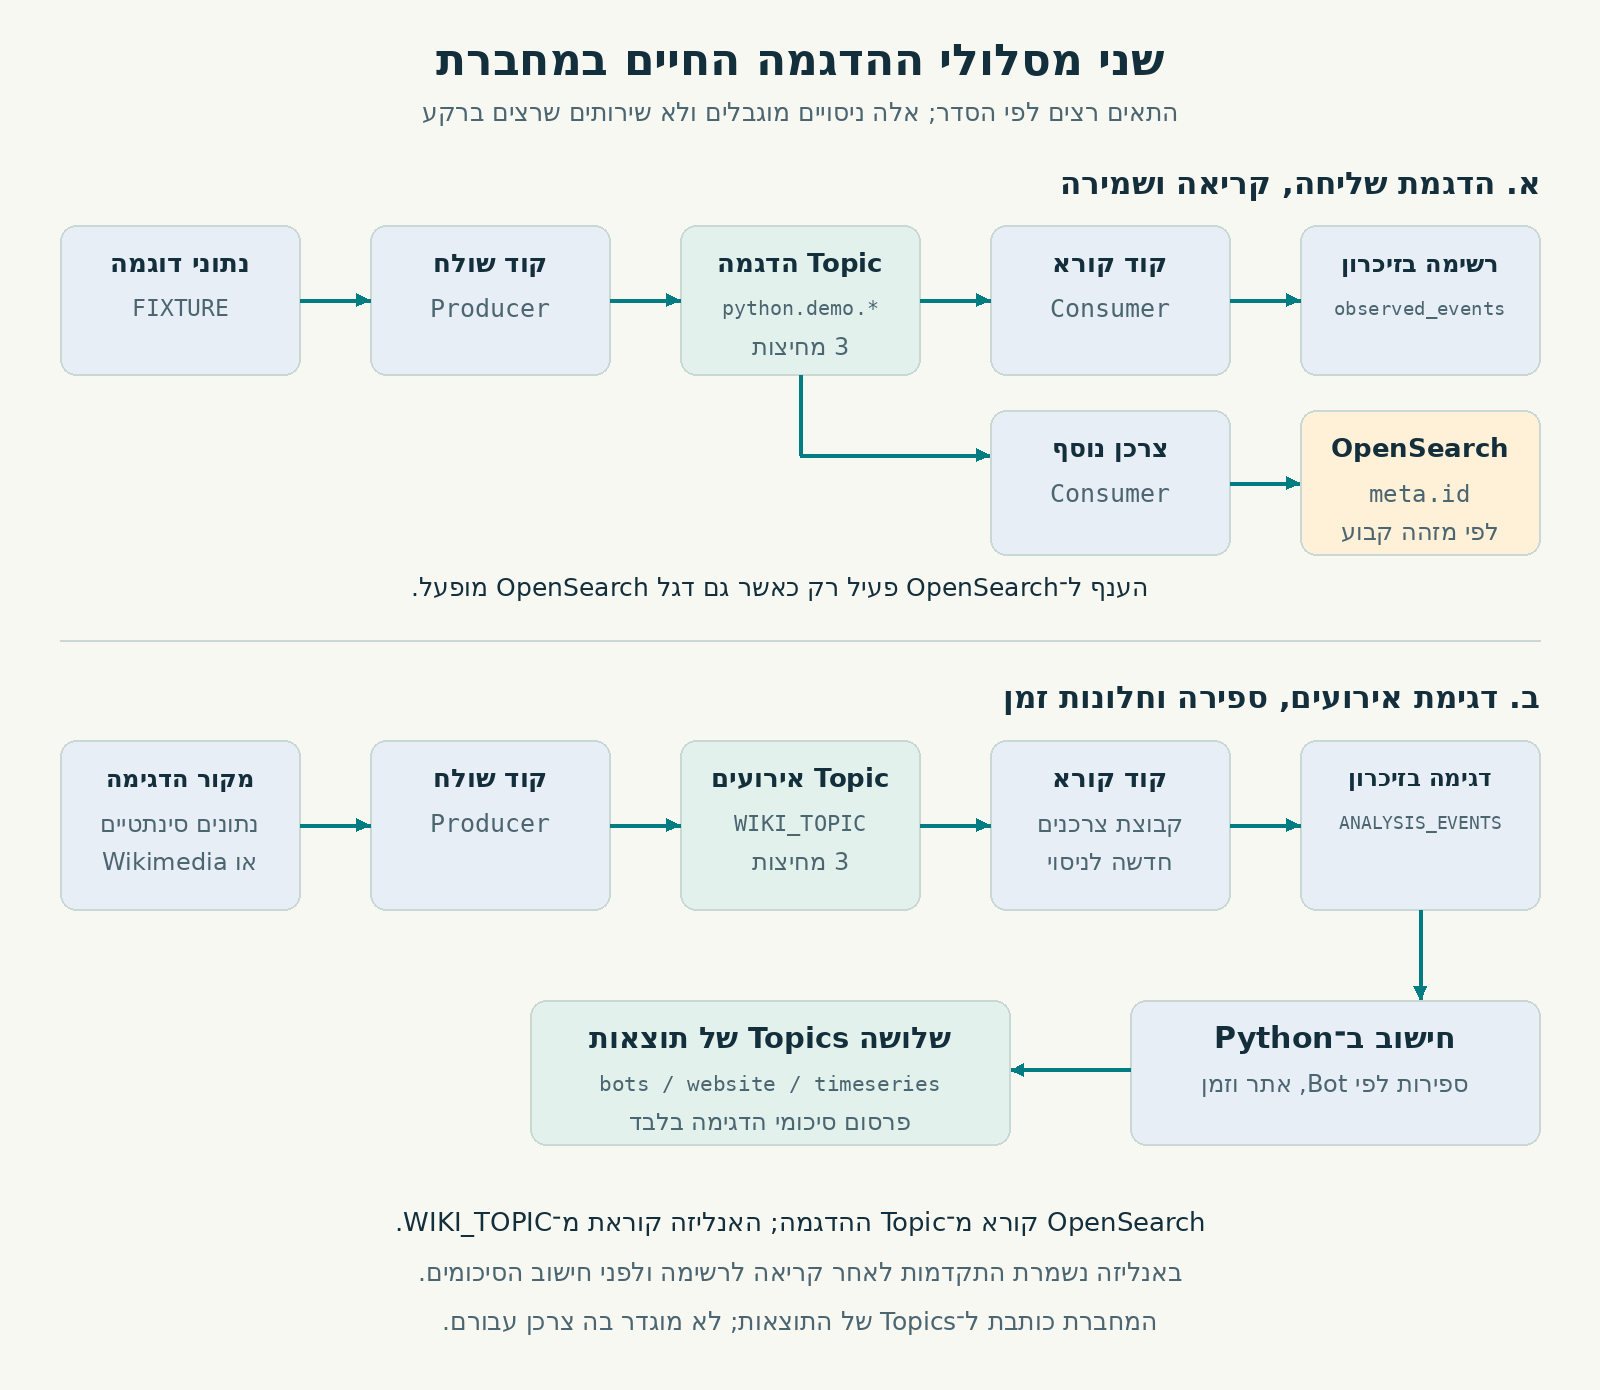

<div dir="rtl" lang="he" style="text-align:right;line-height:1.65"><p>OpenSearch קורא מה־Topic של הדגמת הנתונים הסינתטיים. מסלול Wikimedia והניתוח משתמש ב־Topic אחר. הדגמת Kafka הבסיסית יכולה לפעול כאשר שתי ההרחבות כבויות. כל שלב הוא ריצה מוגבלת, לא שירות רציף.</p></div>

<div dir="rtl" lang="he" style="text-align:right;line-height:1.65">
<h2>שלב 10: חיבור אופציונלי ל־OpenSearch</h2>
<p>משתמשים בשרת מעבדה תואם ל־<code dir="ltr" style="direction:ltr;unicode-bidi:isolate">opensearch-py 3.2.0</code>, למשל OpenSearch 3.x.
לא מחברים אוטומטית את הלקוח החדש ל־Compose הישן של המאגר, שמכיל OpenSearch 1.2.4.</p>
<p>מגדירים מחוץ למחברת את <code dir="ltr" style="direction:ltr;unicode-bidi:isolate">OPENSEARCH_URL</code> ככתובת HTTPS,
ואם נדרש גם <code dir="ltr" style="direction:ltr;unicode-bidi:isolate">OPENSEARCH_USERNAME</code>, <code dir="ltr" style="direction:ltr;unicode-bidi:isolate">OPENSEARCH_PASSWORD</code>
ו־<code dir="ltr" style="direction:ltr;unicode-bidi:isolate">OPENSEARCH_CA_CERT</code>. אין להדביק סיסמאות בקובץ.</p>
<p>אימות תעודת TLS נשאר פעיל. נכתוב רק לאינדקס מעבדה ששמו מתחיל ב־<code dir="ltr" style="direction:ltr;unicode-bidi:isolate">wikimedia-lesson-</code>
ומסתיים ב־<code dir="ltr" style="direction:ltr;unicode-bidi:isolate">RUN_ID</code> של הניסוי.
בדוגמה פשוטה זו כל בקשת <code dir="ltr" style="direction:ltr;unicode-bidi:isolate">index</code> נבדקת בנפרד לפני Commit.</p>
</div>

In [ ]:
OPENSEARCH_INDEX = f"wikimedia-lesson-{RUN_ID}"

def create_opensearch_client():
    from opensearchpy import OpenSearch
    url = os.environ.get("OPENSEARCH_URL", "")
    parsed = urlparse(url)
    if parsed.scheme != "https" or not parsed.hostname or parsed.username:
        raise ValueError("Set OPENSEARCH_URL to HTTPS, without embedded credentials")
    user = os.environ.get("OPENSEARCH_USERNAME")
    password = os.environ.get("OPENSEARCH_PASSWORD")
    if bool(user) != bool(password):
        raise ValueError("Set both OPENSEARCH_USERNAME and OPENSEARCH_PASSWORD")
    options = {"hosts": [url], "verify_certs": True,
               "timeout": 5, "max_retries": 0, "retry_on_timeout": False}
    if user:
        options["http_auth"] = (user, password)
    if os.environ.get("OPENSEARCH_CA_CERT"):
        options["ca_certs"] = os.environ["OPENSEARCH_CA_CERT"]
    return OpenSearch(**options)

def index_event(client, event):
    result = client.index(index=OPENSEARCH_INDEX, id=event["meta"]["id"],
                          body=event, request_timeout=5)
    if result.get("result") not in {"created", "updated"}:
        raise RuntimeError("OpenSearch did not confirm indexing")


In [ ]:
if RUN_LIVE_OPENSEARCH:
    if not RUN_LIVE_KAFKA:
        raise ValueError("Enable RUN_LIVE_KAFKA for this Kafka-to-OpenSearch lesson")
    os_client = create_opensearch_client()
    try:
        if not os_client.indices.exists(index=OPENSEARCH_INDEX, request_timeout=5):
            os_client.indices.create(index=OPENSEARCH_INDEX, request_timeout=5)
        sink_receipts = consume_events(
            TOPIC, "python-opensearch-demo", lambda event: index_event(os_client, event),
            MAX_MESSAGES, READ_DEADLINE_SECONDS,
        )
        print("LIVE indexed and committed:", len(sink_receipts))
    finally:
        os_client.close()
else:
    print("OpenSearch skipped. The previous offline crash experiment remains available.")


<div dir="rtl" lang="he" style="text-align:right;line-height:1.65">
<h2>תרגיל 3 — כשל ביעד ומניעת דילוג</h2>
<p>כתיבת רשומה במחיצה 0 נכשלת. מדוע לא מספיק להימנע מ־Commit רק עבורה ולהמשיך כרגיל?</p>
<details><summary>פתרון מוצע</summary>
<p>Commit של רשומה מאוחרת באותה מחיצה עלול לשמור מיקום שמדלג מעל הרשומה שנכשלה.
לכן הפונקציה שלנו עוצרת עם הכשל. בהפעלה חוזרת היא יכולה לעבד שוב מהמיקום השמור.
פתרון מתקדם דורש מעקב אחר רצף הצלחות לכל מחיצה או העברה מאומתת לערוץ שגיאות.</p>
<p>ב־Bulk API יש לבדוק גם הצלחה של כל פריט. תגובת HTTP תקינה אינה מוכיחה שכל הפריטים נכתבו.
זו אחת הנקודות שחסרות בדוגמת ה־OpenSearch המקורית במאגר.</p></details>
</div>

<div dir="rtl" lang="he" style="text-align:right;line-height:1.65">
<h2>שלב 11: פענוח זרם Server-Sent Events</h2>
<p>Wikimedia EventStreams משתמש ב־SSE. שורה ריקה מסיימת אירוע; אירוע יכול לכלול כמה שורות
<code dir="ltr" style="direction:ltr;unicode-bidi:isolate">data:</code>, שיש לחבר באמצעות תו שורה חדשה. שורות שמתחילות בנקודתיים הן הערות.</p>
<p>נפריד בין פענוח הפרוטוקול לבין בקשת הרשת. כך אפשר לבדוק את הפענוח גם ללא אינטרנט.</p>
</div>

In [ ]:
def parse_sse_blocks(lines, deadline=None, max_lines=20000):
    data, event_type, size = [], "message", 0
    for line in islice(lines, max_lines):
        if deadline is not None and time.monotonic() >= deadline:
            return
        if isinstance(line, bytes):
            line = line.decode("utf-8")
        line = line.rstrip("\r\n")
        if line == "":
            if data:
                yield {"event": event_type, "data": "\n".join(data)}
            data, event_type, size = [], "message", 0
            continue
        if line.startswith(":"):
            continue
        field, separator, value = line.partition(":")
        if value.startswith(" "):
            value = value[1:]
        if field == "data":
            size += len(value)
            if size > 262144:
                raise ValueError("SSE event exceeds this lesson's size limit")
            data.append(value)
        elif field == "event":
            event_type = value or "message"
    # An incomplete final event without a blank separator is not dispatched.


In [ ]:
json_lines = json.dumps(FIXTURE[0], indent=2).splitlines()
sample_sse = [": heartbeat", "event: message", "id: example"]
sample_sse += ["data: " + line for line in json_lines] + [""]
blocks = list(parse_sse_blocks(sample_sse))
assert len(blocks) == 1
assert decode_event(blocks[0]["data"]) == FIXTURE[0]
assert list(parse_sse_blocks(["data: incomplete"])) == []
print("SSE parser: multi-line data, comments and event boundary checks passed.")


<div dir="rtl" lang="he" style="text-align:right;line-height:1.65">
<h2>קריאה חיה מוגבלת</h2>
<p>התא הבא רק מגדיר פונקציה. ההפעלה תתרחש בשלב הבא ורק אם
<code dir="ltr" style="direction:ltr;unicode-bidi:isolate">RUN_LIVE_WIKIMEDIA=True</code>. נקרא עד עשרה אירועים מתאימים, עם timeout לחיבור ולקריאה ומגבלת זמן מיטבית.</p>
<p>התוכן הציבורי עשוי להשתנות. המחברת מסננת אירועי Canary ומתעלמת מאירועים שאינם כוללים את השדות הדרושים לתרגיל.
היא אינה מנגנון קליטה רציף עם שחזור, שמירת מזהה SSE או הבטחת מסירה.</p>
</div>

In [ ]:
def read_wikimedia_events(limit=10, max_seconds=20):
    import requests
    endpoint = "https://stream.wikimedia.org/v2/stream/recentchange"
    headers = {"Accept": "text/event-stream", "User-Agent": os.environ.get(
        "WIKIMEDIA_USER_AGENT", "KafkaPythonLesson/1.0 (bounded educational demo)")}
    events, skipped = [], 0
    deadline = time.monotonic() + max_seconds
    with requests.get(endpoint, headers=headers, stream=True, timeout=(5, 3)) as response:
        response.raise_for_status()
        response.encoding = "utf-8"
        lines = response.iter_lines(chunk_size=1, decode_unicode=True)
        for block in parse_sse_blocks(lines, deadline=deadline):
            if block["event"] != "message":
                continue
            try:
                event = decode_event(block["data"])
                if event["meta"].get("domain") == "canary":
                    skipped += 1
                    continue
            except (ValueError, TypeError, KeyError, AttributeError):
                skipped += 1
                continue
            events.append(event)
            if len(events) >= limit:
                break
    print("LIVE Wikimedia events:", len(events), "skipped:", skipped)
    return events


<div dir="rtl" lang="he" style="text-align:right;line-height:1.65">
<h2>שלב 12: מקור אירועים ופרסום ל־Kafka</h2>
<p>אפשר ללמוד את אותו ממשק עם מקור סינתטי או עם דגימת Wikimedia חיה.
הפעלת מקור חי אינה מפעילה Kafka אוטומטית, ולהפך.</p>
<p>בקריאה חיה מומלץ להגדיר <code dir="ltr" style="direction:ltr;unicode-bidi:isolate">WIKIMEDIA_USER_AGENT</code> עם שם יישום ופרטי קשר מתאימים.
שגיאת רשת נמסרת למשתמש; אין מעבר שקט לנתונים סינתטיים שמתיימרים להיות נתונים חיים.</p>
</div>

In [ ]:
if RUN_LIVE_WIKIMEDIA:
    recent_events = read_wikimedia_events(limit=MAX_MESSAGES)
    source_label = "LIVE Wikimedia sample"
else:
    recent_events = copy.deepcopy(FIXTURE)
    source_label = "SYNTHETIC offline fixture"
print("Source:", source_label, "| events:", len(recent_events))


In [ ]:
if RUN_LIVE_KAFKA:
    wiki_delivery = publish_json_rows(
        recent_events, WIKI_TOPIC, key_fn=lambda event: event["server_name"],
        limit=MAX_MESSAGES,
    )
    print("LIVE Kafka confirmed:", wiki_delivery["confirmed"], "source:", source_label)
else:
    print("Kafka publish skipped. Source data remains local in recent_events.")

if RUN_LIVE_KAFKA:
    ANALYSIS_EVENTS = []
    analysis_group = "python-analysis-" + uuid.uuid4().hex[:8]
    analysis_receipts = consume_events(
        WIKI_TOPIC, analysis_group, ANALYSIS_EVENTS.append,
        MAX_MESSAGES, READ_DEADLINE_SECONDS,
    )
    print("LIVE Kafka sample for analysis:", len(ANALYSIS_EVENTS))
else:
    ANALYSIS_EVENTS = copy.deepcopy(recent_events)
assert len(ANALYSIS_EVENTS) <= MAX_MESSAGES


<div dir="rtl" lang="he" style="text-align:right;line-height:1.65">
<h2>הרחבת המסלול ליעד</h2>
<p>שלב OpenSearch קרא את <code dir="ltr" style="direction:ltr;unicode-bidi:isolate">TOPIC</code> כדי להדגים את הנתונים הסינתטיים הראשונים.
כדי להמשיך עם Topic של Wikimedia, משתמשים באותה פונקציית <code dir="ltr" style="direction:ltr;unicode-bidi:isolate">consume_events</code>
עם <code dir="ltr" style="direction:ltr;unicode-bidi:isolate">WIKI_TOPIC</code>, עם group ייעודי ועם <code dir="ltr" style="direction:ltr;unicode-bidi:isolate">index_event</code> כפעולת העיבוד.</p>
<p>אין להריץ שוב את כל המחברת כדי לקבל זרם רציף. זו דגימה תחומה לצורך למידה.
ה־deadline של SSE נבדק בין שורות, ו־HTTP timeout מגביל המתנה לרשת; זה אינו שעון עצר קשיח לכל המערכת.</p>
<p>כאשר Kafka פעיל, הספירות בשלבים הבאים משתמשות בדגימה שנקראה ממנו בקבוצה חדשה.
ה־Topic מבודד לפי <code dir="ltr" style="direction:ltr;unicode-bidi:isolate">RUN_ID</code>. אם מריצים שוב תא פרסום באותו ניסוי, הוא יכול להכיל כמה אצוות,
וקבוצה חדשה תקרא מתחילת ההיסטוריה הזמינה, לא בהכרח מהאצווה האחרונה.
תוצאת קריאה חלקית או ריקה נשארת גלויה ואינה מוחלפת בשקט בנתונים מקומיים.</p>
</div>

<div dir="rtl" lang="he" style="text-align:right;line-height:1.65">
<h2>שלב 13: ספירה מצטברת ב־Python</h2>
<p>נחשב ספירות באמצעות <code dir="ltr" style="direction:ltr;unicode-bidi:isolate">collections.Counter</code>. זהו עיבוד של רשימה מקומית בזיכרון,
לא הרצה של Kafka Streams ולא מנגנון State Store מנוהל.</p>
<p>נשתמש בקטגוריות <code dir="ltr" style="direction:ltr;unicode-bidi:isolate">bot</code>, <code dir="ltr" style="direction:ltr;unicode-bidi:isolate">non-bot</code> ו־<code dir="ltr" style="direction:ltr;unicode-bidi:isolate">invalid</code>.
השם האחרון הוא בחירה לימודית שלנו; בקוד המקורי מופיעה הקטגוריה <code dir="ltr" style="direction:ltr;unicode-bidi:isolate">parse-error</code>.</p>
</div>

In [ ]:
def classify_bot(event):
    marker = event.get("bot") if isinstance(event, dict) else None
    if not isinstance(marker, bool):
        return "invalid"
    return "bot" if marker else "non-bot"

bot_counts = Counter(classify_bot(event) for event in ANALYSIS_EVENTS)
bot_rows = [{"category": category, "count": count}
            for category, count in sorted(bot_counts.items())]
print("Counts:", dict(bot_counts))
print("Invalid example:", classify_bot({"bot": "yes"}))


In [ ]:
assert sum(bot_counts.values()) == len(ANALYSIS_EVENTS)
assert classify_bot({}) == "invalid"
if not RUN_LIVE_WIKIMEDIA and not RUN_LIVE_KAFKA:
    assert bot_counts == Counter({"bot": 6, "non-bot": 4})
    print("Expected synthetic counts verified: bot=6, non-bot=4.")
else:
    print("Live sample counts vary; only the total-count invariant was checked.")


<div dir="rtl" lang="he" style="text-align:right;line-height:1.65">
<h2>מיפוי למודול המקורי</h2>
<p>במאגר, <a href="https://github.com/conduktor/kafka-beginners-course/blob/bce0dfe60b076b9affc2148a8783faed8dc9559d/kafka-streams-wikimedia/src/main/java/io/conduktor/demos/kafka/streams/wikimedia/processor/BotCountStreamBuilder.java">BotCountStreamBuilder</a>
מסווג, מקבץ וסופר, ואז כותב JSON ל־<code dir="ltr" style="direction:ltr;unicode-bidi:isolate">wikimedia.stats.bots</code>.</p>
<p>כאן נשמר snapshot מקומי של הדגימה. הוא אינו מתעדכן ברקע ואינו משוחזר אוטומטית לאחר סגירת ה־kernel.
פורמט פלט ההוראה <code dir="ltr" style="direction:ltr;unicode-bidi:isolate">{"category": "bot", "count": 6}</code> שונה מה־JSON של הדוגמה המקורית.</p>
</div>

<div dir="rtl" lang="he" style="text-align:right;line-height:1.65">
<h2>שלב 14: חלונות זמן לפי timestamp מפורש</h2>
<p>נשתמש בזמן <code dir="ltr" style="direction:ltr;unicode-bidi:isolate">meta.dt</code> של האירוע ונעגל כלפי מטה לגבול חלון UTC.
חלון כולל את הגבול התחתון שלו ואינו כולל את הגבול העליון.</p>
<p>נספור לפי אתר בחלונות של דקה, ובמקביל את כלל האירועים בחלונות של עשר שניות.
זהו חישוב Batch מקומי על דגימה, לא חיקוי של Stream-time או Grace של Kafka Streams.</p>
</div>

In [ ]:
def utc_text(milliseconds):
    return datetime.fromtimestamp(milliseconds / 1000, timezone.utc).isoformat()

def aggregate_windows(events, width_seconds, key_fn):
    if width_seconds <= 0:
        raise ValueError("Window size must be positive")
    width_ms = width_seconds * 1000
    counts = Counter()
    for event in events:
        start = (event_millis(event) // width_ms) * width_ms
        counts[(key_fn(event), start)] += 1
    return [{"key": key, "start_ms": start, "start": utc_text(start),
             "end": utc_text(start + width_ms), "count": count}
            for (key, start), count in sorted(counts.items())]

site_rows = aggregate_windows(ANALYSIS_EVENTS, 60, lambda event: event["server_name"])
time_rows = aggregate_windows(ANALYSIS_EVENTS, 10, lambda event: "all")


In [ ]:
print("Per site / one-minute windows:")
for row in site_rows:
    print(row["key"], row["start"], "count=", row["count"])
print("All events / ten-second windows:")
for row in time_rows:
    print(row["start"], "count=", row["count"])
assert sum(row["count"] for row in site_rows) == len(ANALYSIS_EVENTS)
assert sum(row["count"] for row in time_rows) == len(ANALYSIS_EVENTS)
if not RUN_LIVE_WIKIMEDIA and not RUN_LIVE_KAFKA:
    assert [row["count"] for row in time_rows] == [3, 2, 2, 1, 2]


<div dir="rtl" lang="he" style="text-align:right;line-height:1.65">
<h2>תוצאה צפויה לדגימה הסינתטית</h2>
<p>חלונות עשר השניות שאינם ריקים מתחילים ב־12:00:00, 12:00:10, 12:00:20, 12:00:40 ו־12:01:00.
הספירות הן בהתאמה <code dir="ltr" style="direction:ltr;unicode-bidi:isolate">[3, 2, 2, 1, 2]</code>.</p>
<p>אירוע ב־12:00:10 שייך לחלון שמתחיל ב־12:00:10, ולא לקודמו.
חלון ללא אירועים אינו מופיע ברשימה הזאת. יצירת סדרת זמן עם אפסים היא פעולה נוספת.</p>
</div>

<div dir="rtl" lang="he" style="text-align:right;line-height:1.65">
<h2>שלב 15: אירוע שמגיע מאוחר</h2>
<p>נוסיף בסוף הרשימה אירוע שזמנו 12:00:03, אף שכבר ראינו אירועים מ־12:01:05.
החישוב המקומי שלנו כולל אותו בחלון הישן, כי הוא מחשב מחדש על כל הרשימה.</p>
<p>הדבר <b>אינו משחזר את מדיניות zero-grace</b> שבדוגמת Kafka Streams.
במערכת זרמים ההחלטה לקבל אירוע מאוחר תלויה ב־stream-time, בגבולות החלון וב־grace.</p>
</div>

In [ ]:
late_event = copy.deepcopy(FIXTURE[0])
late_event["meta"]["id"] = "synthetic-late"
late_event["meta"]["dt"] = (BASE_TIME + timedelta(seconds=3)).isoformat()
arrival_order = copy.deepcopy(FIXTURE) + [late_event]
late_rows = aggregate_windows(arrival_order, 10, lambda event: "all")
first_window = late_rows[0]
assert first_window["count"] == 4
assert sum(row["count"] for row in late_rows) == 11
print("Last arrival timestamp:", arrival_order[-1]["meta"]["dt"])
print("Recomputed first window count:", first_window["count"])


In [ ]:
bot_only = [event for event in FIXTURE if classify_bot(event) == "bot"]
bot_site_windows = aggregate_windows(bot_only, 60, lambda event: event["server_name"])
assert sum(row["count"] for row in bot_site_windows) == 6
print("Bot events per site and minute:")
for row in bot_site_windows:
    print(row["key"], row["start"], row["count"])


<div dir="rtl" lang="he" style="text-align:right;line-height:1.65">
<h2>תרגיל 4 — תכנון עיבוד לפי אתר</h2>
<p>נדרש לחשב אירועי שינוי של Bots בכל אתר בחלונות של דקה. הסבירו את סדר הסינון, הקיבוץ והספירה,
והגדירו מדיניות לאירוע מאוחר ול־JSON פגום.</p>
<details><summary>פתרון מוצע</summary>
<p>מפענחים ומוודאים שדות, מסננים <code dir="ltr" style="direction:ltr;unicode-bidi:isolate">bot=True</code>, מקבצים לפי אתר ותחילת חלון, ואז סופרים.
בקלט הסינתטי יש שלושה אירועי Bot באתר האנגלי ושניים באתר העברי בדקה הראשונה,
ועוד אירוע Bot באתר האנגלי בדקה השנייה.</p>
<p>במערכת חיה מחליטים במפורש אם לעדכן חלון ישן, לאפשר grace מוגדר או להפנות את האירוע לערוץ נפרד.
קוד ה־Counter המקומי אינו מספק לבדו מדיניות איחור, checkpoint או שחזור.</p></details>
</div>

<div dir="rtl" lang="he" style="text-align:right;line-height:1.65">
<h2>שלב 16: שלושת הפלטים ומיפוי למאגר</h2>
<table style="border-collapse:collapse;width:100%" border="1" cellpadding="8">
<tr><th>הפלט המקורי</th><th>העיבוד במחברת</th><th>Topic הפלט הלימודי</th></tr>
<tr><td><code dir="ltr" style="direction:ltr;unicode-bidi:isolate">wikimedia.stats.bots</code></td><td>ספירת Bot/non-bot בדגימה</td><td><code dir="ltr" style="direction:ltr;unicode-bidi:isolate">python.wikimedia.stats.bots.&lt;RUN_ID&gt;</code></td></tr>
<tr><td><code dir="ltr" style="direction:ltr;unicode-bidi:isolate">wikimedia.stats.website</code></td><td>ספירה לפי אתר ודקה</td><td><code dir="ltr" style="direction:ltr;unicode-bidi:isolate">python.wikimedia.stats.website.&lt;RUN_ID&gt;</code></td></tr>
<tr><td><code dir="ltr" style="direction:ltr;unicode-bidi:isolate">wikimedia.stats.timeseries</code></td><td>ספירת אירועים בחלונות של 10 שניות</td><td><code dir="ltr" style="direction:ltr;unicode-bidi:isolate">python.wikimedia.stats.timeseries.&lt;RUN_ID&gt;</code></td></tr>
</table>
<p>אלה Topics נפרדים עם פורמט JSON לימודי. הם אינם תחליף בינארי תואם לפלט Kafka Streams המקורי.
במסלול חי נפרסם snapshots של הדגימה, ולא State Store מתמשך.</p>
</div>

In [ ]:
if RUN_LIVE_KAFKA:
    reports = {
        "bots": publish_json_rows(bot_rows, RESULT_TOPICS["bots"],
                                  lambda row: row["category"], limit=100),
        "websites": publish_json_rows(site_rows, RESULT_TOPICS["websites"],
                                      lambda row: row["key"], limit=100),
        "timeseries": publish_json_rows(time_rows, RESULT_TOPICS["timeseries"],
                                        lambda row: row["key"], limit=100),
    }
    print({name: report["confirmed"] for name, report in reports.items()})
else:
    print("OFFLINE output snapshots:",
          {"bots": len(bot_rows), "websites": len(site_rows), "timeseries": len(time_rows)})


In [ ]:
assert len(FIXTURE) == 10
assert decode_event(encode_event(FIXTURE[0])[1]) == FIXTURE[0]
assert len(documents) == 10 and sum(write_attempts.values()) == 11
assert checkpoint["next_offset"] == 10
assert first_window["count"] == 4
if not any([RUN_LIVE_KAFKA, RUN_LIVE_WIKIMEDIA, RUN_LIVE_OPENSEARCH]):
    assert bot_counts == Counter({"bot": 6, "non-bot": 4})
    assert [row["count"] for row in time_rows] == [3, 2, 2, 1, 2]
    print("PASS: offline data, JSON, SSE, replay, crash recovery, counters and windows.")
    print("No Kafka, Wikimedia or OpenSearch connection was made by the lesson.")
else:
    print("Local invariants checked. Review the individual live results above.")


<div dir="rtl" lang="he" style="text-align:right;line-height:1.65">
<h2>איך לפרש את הפלטים?</h2>
<table>
<thead><tr><th>הפלט</th><th>מה הוא אומר</th></tr></thead>
<tbody>
<tr><td><code dir="ltr" style="direction:ltr;unicode-bidi:isolate">bot=6, non-bot=4</code></td><td>שישה מתוך עשרת האירועים הם Bots וארבעה אינם Bots.</td></tr>
<tr><td><code dir="ltr" style="direction:ltr;unicode-bidi:isolate">{'bots': 2, 'websites': 5, 'timeseries': 5}</code></td><td>מספר <b>שורות הסיכום</b>. שתי שורות Bots הן שתי הקטגוריות, ולא שני אירועים.</td></tr>
<tr><td><code dir="ltr" style="direction:ltr;unicode-bidi:isolate">[3, 2, 2, 1, 2]</code></td><td>מספר האירועים בחמשת חלונות עשר השניות שאינם ריקים. חלון ריק אינו מופיע.</td></tr>
<tr><td><code dir="ltr" style="direction:ltr;unicode-bidi:isolate">11 writes / 10 documents</code></td><td>בניסוי הכשל האירוע הרביעי נכתב שוב עם אותו מזהה. יש ניסיון נוסף, אך הוא מעדכן מסמך קיים.</td></tr>
</tbody></table>
<p>ה־“restart” בניסוי הכשל הוא קריאה חוזרת ל־<code dir="ltr" style="direction:ltr;unicode-bidi:isolate">process_offline()</code> באותו Kernel;
אין צורך לאתחל את המחברת בתוך הניסוי. הודעת <code dir="ltr" style="direction:ltr;unicode-bidi:isolate">PASS</code> מאשרת את הבדיקות המקומיות,
ואינה מוכיחה שחיבור חי לשרת נבדק.</p>
</div>

<div dir="rtl" lang="he" style="text-align:right;line-height:1.65">
<h2>בדיקה ידנית של המסלול החי</h2>
<ol><li>בדקו שה־Broker זמין ושכל Topics המעבדה מכילים שלוש מחיצות.</li>
<li>ודאו שכל אישורי ה־Producer התקבלו ללא שגיאות, ושהקוד לא רק הגיע ל־flush.</li>
<li>בדקו צרכן עם אותה קבוצה ואחר כך קבוצה חדשה, ותעדו את ההבדל.</li>
<li>בשרת OpenSearch תואם, בדקו מסמך לפי <code dir="ltr" style="direction:ltr;unicode-bidi:isolate">meta.id</code> והרצה חוזרת עם אותו ID.</li>
<li>הפסיקו זמנית יעד מעבדה ובדקו שהצרכן נעצר לפני שמירת התקדמות מעל כשל.</li>
<li>הפעילו דגימת Wikimedia מוגבלת ובדקו את ה־User-Agent, שגיאות הפענוח וה־timestamps.</li></ol>
<p><b>סטטוס בדיקה של קובץ זה:</b> תאי הקוד של מסלול ברירת המחדל הורצו לפי סדרם במרחב שמות Python נקי,
כולל assertions, לכידת הפלטים ושמירתם במחברת. זו בדיקת Python של מסלול הלמידה, ולא בדיקת ממשק Jupyter.
מסלולי Kafka, Wikimedia ו־OpenSearch החיים לא הורצו ולא נבדקו מול שירותים חיצוניים.</p>
<p>המחברת אינה מערכת ייצור. אין בה קליטה רציפה מובטחת, Kafka Streams runtime, state מנוהל,
שחזור אוטומטי של ה־Counter, טרנזקציה אטומית עם OpenSearch או Exactly-once כללי.</p>
</div>

<div dir="rtl" lang="he" style="text-align:right;line-height:1.65">
<h2>מקורות וקריאה נוספת</h2>
<ul>
<li><a href="https://www.python.org/downloads/release/python-31312/">Python 3.13.12 — גרסת היעד של סביבת השיעור</a>.</li>
<li><a href="https://docs.astral.sh/uv/guides/integration/jupyter/">uv — עבודה עם Jupyter ו־Kernel של הפרויקט</a>;
<a href="https://cursor.com/for/data-science">Cursor — Data Science ומחברות</a>.</li>
<li><a href="https://github.com/conduktor/kafka-beginners-course">Conduktor — Kafka for Beginners</a>, קוד המקור שנבדק ב־commit <code dir="ltr" style="direction:ltr;unicode-bidi:isolate">bce0dfe60b076b9affc2148a8783faed8dc9559d</code>.</li>
<li><a href="https://github.com/conduktor/kafka-beginners-course/blob/bce0dfe60b076b9affc2148a8783faed8dc9559d/kafka-basics/src/main/java/io/conduktor/demos/kafka/ProducerDemoWithCallback.java">Producer ו־Callback במאגר</a>;
<a href="https://github.com/conduktor/kafka-beginners-course/blob/bce0dfe60b076b9affc2148a8783faed8dc9559d/kafka-basics/src/main/java/io/conduktor/demos/kafka/ConsumerDemoWithShutdown.java">Consumer וסגירה מסודרת</a>.</li>
<li><a href="https://github.com/conduktor/kafka-beginners-course/blob/bce0dfe60b076b9affc2148a8783faed8dc9559d/kafka-producer-wikimedia/src/main/java/io/conduktor/demos/kafka/wikimedia/WikimediaChangesProducer.java">מקור Wikimedia במאגר</a>;
<a href="https://github.com/conduktor/kafka-beginners-course/blob/bce0dfe60b076b9affc2148a8783faed8dc9559d/kafka-consumer-opensearch/src/main/java/io/conduktor/demos/kafka/opensearch/OpenSearchConsumer.java">יעד OpenSearch במאגר</a>.</li>
<li><a href="https://github.com/conduktor/kafka-beginners-course/blob/bce0dfe60b076b9affc2148a8783faed8dc9559d/kafka-streams-wikimedia/src/main/java/io/conduktor/demos/kafka/streams/wikimedia/WikimediaStreamsApp.java">שלושת עיבודי Streams במאגר</a>.</li>
<li><a href="https://kafka.apache.org/44/getting-started/quickstart/">Apache Kafka Quickstart</a>;
<a href="https://kafka.apache.org/intro/">מודל האירועים והמחיצות</a>;
<a href="https://kafka.apache.org/44/streams/">Kafka Streams</a>.</li>
<li><a href="https://docs.confluent.io/platform/current/clients/confluent-kafka-python/html/index.html">Confluent Python API</a>;
<a href="https://github.com/confluentinc/librdkafka/blob/master/CONFIGURATION.md">librdkafka configuration</a>.</li>
<li><a href="https://wikitech.wikimedia.org/wiki/Event_Platform/EventStreams">Wikimedia EventStreams</a>;
<a href="https://html.spec.whatwg.org/multipage/server-sent-events.html">תקן SSE</a>.</li>
<li><a href="https://docs.opensearch.org/latest/clients/python-low-level/">OpenSearch Python client</a>;
<a href="https://docs.opensearch.org/latest/api-reference/document-apis/bulk/">OpenSearch Bulk API</a>.</li>
<li>גרסאות חבילות שנבחרו:
<a href="https://pypi.org/project/confluent-kafka/2.16.2/">confluent-kafka 2.16.2</a>,
<a href="https://pypi.org/project/requests/2.34.2/">requests 2.34.2</a>,
<a href="https://pypi.org/project/opensearch-py/3.2.0/">opensearch-py 3.2.0</a>.</li>
</ul>
<p>התכנים בעברית, התרגילים והקוד ב־Python הם עיבוד לימודי שנכתב עבור המחברת.
הנתונים הלא מקוונים הם סינתטיים במלואם. אין בקובץ פרטי התחברות או סודות.</p>
</div>